# Practical 10: Wine Dataset Analysis and Principal Component Analysis

## Step 1: Displaying Basic Statistics

## In this step, we load the Wine dataset provided by Scikit-learn and examine its basic statistical properties using the Pandas `describe()` function.

## The Wine dataset contains numerical chemical measurements of wines belonging to three different classes. These measurements include alcohol, malic acid, ash, magnesium, and other chemical properties.

## The `describe()` function displays statistical information such as count, mean, standard deviation, minimum, maximum, and quartiles for each feature. This helps us understand the distribution and range of the variables before performing further analysis.

## We also add the wine class label to the DataFrame so that the observations can be grouped and visualized by class in later steps.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine

# Load the Wine dataset
wine = load_wine()

# Create a DataFrame containing the features
df = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

# Add the target class
df["target"] = wine.target

# Display the first five rows
display(df.head())

# Display basic statistical information
display(df.describe())

# Display the number of records in each class
print("Class distribution:")
print(df["target"].value_counts().sort_index())

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


Class distribution:
target
0    59
1    71
2    48
Name: count, dtype: int64


# What should you understand?

## - df.head() displays the first five records.

## - df.describe() summarizes the numerical features.

## - target represents the three wine classes: 0, 1, and 2.

## - The dataset contains 178 observations and 13 chemical features, plus the target column.

## **Conclusion:** The Wine dataset has been loaded successfully, and its basic statistics have been displayed using the `describe()` function. The dataset's feature distributions and class counts have been examined, providing an initial understanding of the data before visualization and dimensionality reduction.

# Step 2: Boxplot by Output Labels or Classes

## A boxplot is a statistical visualization that summarizes the distribution of a numerical variable.

## It displays the median, lower and upper quartiles, the spread of the observations, and potential outliers. In this step, we create a boxplot of alcohol content for the three wine classes.

## Comparing the boxplots helps us observe how the alcohol measurements differ between classes. This is a single-feature comparison; the classes may overlap, so the plot alone does not establish that alcohol can perfectly distinguish them.

<Figure size 800x500 with 0 Axes>

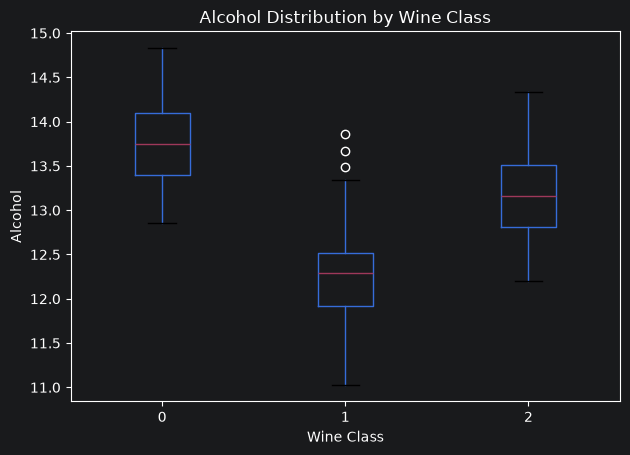

In [2]:
plt.figure(figsize=(8, 5))

df.boxplot(
    column="alcohol",
    by="target",
    grid=False
)

plt.title("Alcohol Distribution by Wine Class")
plt.suptitle("")
plt.xlabel("Wine Class")
plt.ylabel("Alcohol")
plt.tight_layout()
plt.show()

## Conclusion: The boxplot compares the distribution of alcohol content across the three wine classes. Differences in medians and spreads indicate how this feature varies between classes, while any overlap shows that alcohol alone may not completely separate them.

# Step 3: Scatterplot Using Two Variables

## A scatterplot displays the relationship between two numerical variables. Each point represents one observation, and its position is determined by the values of the two selected features.

## In this step, we plot alcohol against color intensity and use different colors to represent the three wine classes. This allows us to visually examine patterns, clusters, and overlaps among the classes.

## The scatterplot provides a two-feature view of the dataset. Some classes may appear more distinct than others, but the visualization uses only two of the dataset's 13 features.

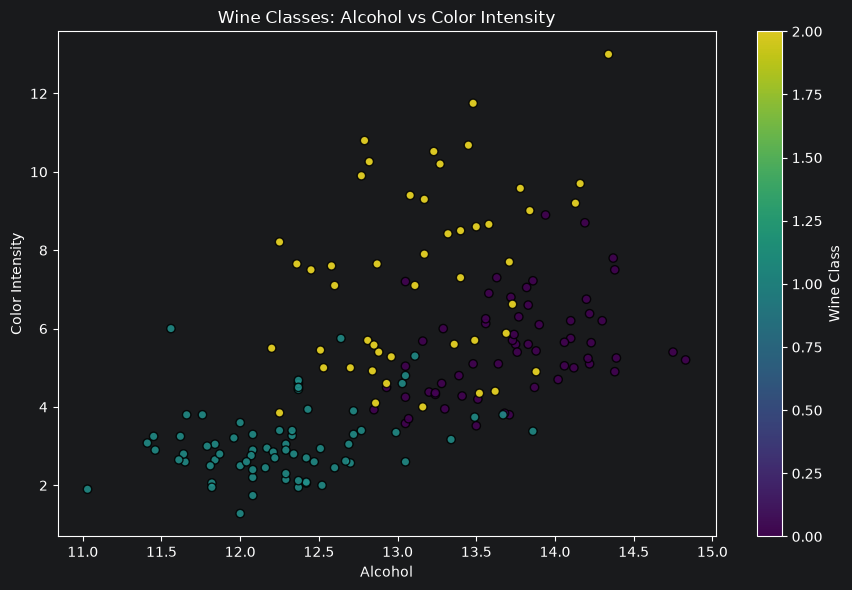

In [3]:
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    df["alcohol"],
    df["color_intensity"],
    c=df["target"],
    cmap="viridis",
    edgecolors="black",
    alpha=0.85
)

plt.xlabel("Alcohol")
plt.ylabel("Color Intensity")
plt.title("Wine Classes: Alcohol vs Color Intensity")

cbar = plt.colorbar(scatter)
cbar.set_label("Wine Class")

plt.tight_layout()
plt.show()

## **Conclusion:** The scatterplot visualizes the relationship between alcohol and color intensity, with points colored according to their wine class. The distribution of points helps us inspect class clusters, relationships between features, and areas of overlap.

# Step 4: Plotting the Covariance Matrix

## **Objective:** To calculate and visualize the covariance between the numerical features of the Wine dataset.

## Covariance indicates how two variables change in relation to each other.

### - **Positive covariance:** Two variables tend to increase or decrease together.

### - **Negative covariance:** When one variable increases, the other tends to decrease.

### - **Covariance near zero:** There is little linear co-variation between the variables.

## The `cov()` function calculates the covariance between each pair of numerical features. The `imshow()` function displays the resulting matrix as a heatmap, and the color bar helps us interpret the values.

## The target column is excluded because it represents the class labels, not a wine measurement. Since the features have different scales, the covariance values may vary greatly in magnitude.

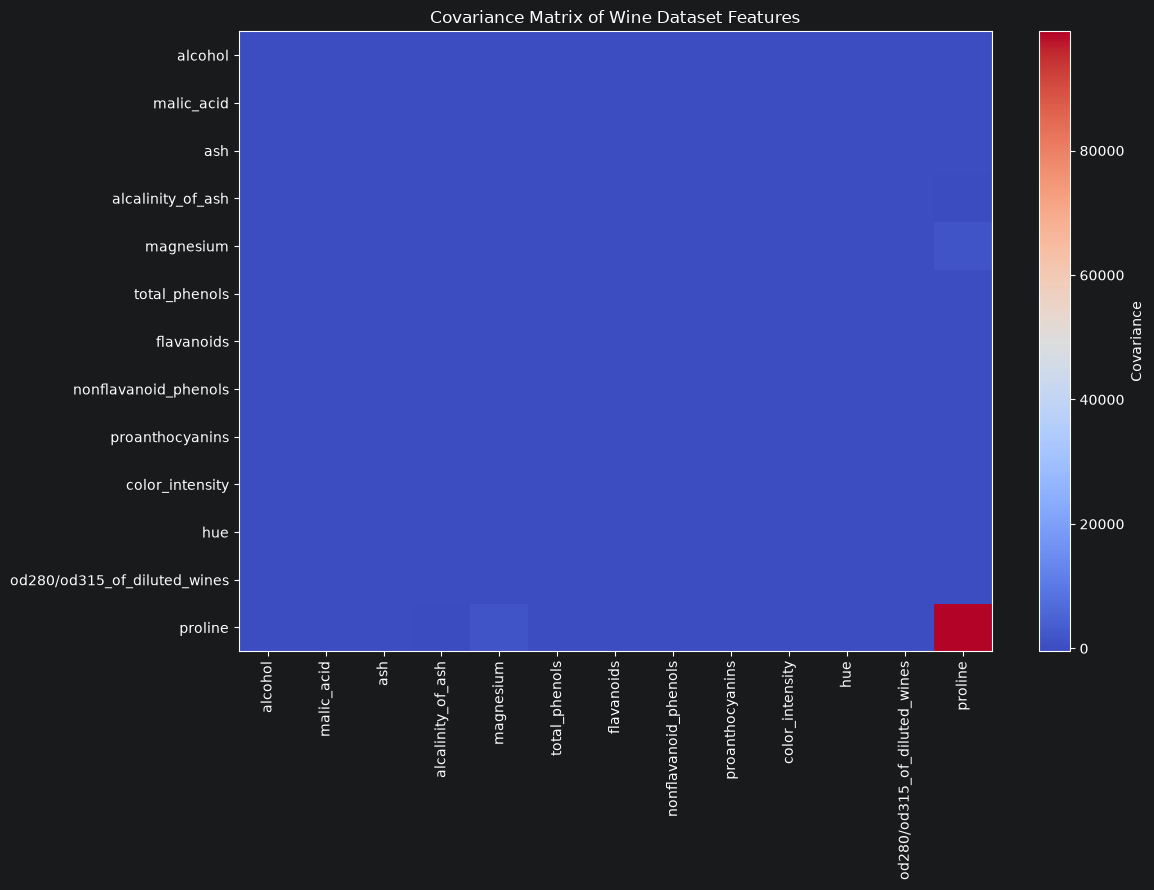

In [4]:
# Select only the 13 numerical features
feature_data = df.drop(columns=["target"])

# Calculate the covariance matrix
cov_matrix = feature_data.cov()

# Plot the covariance matrix
plt.figure(figsize=(12, 9))

plt.imshow(cov_matrix, cmap="coolwarm", aspect="auto")
plt.colorbar(label="Covariance")

plt.xticks(
    range(len(cov_matrix.columns)),
    cov_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(cov_matrix.columns)),
    cov_matrix.columns
)

plt.title("Covariance Matrix of Wine Dataset Features")
plt.tight_layout()
plt.show()

# Conclusion

## The covariance matrix was calculated and visualized using a heatmap. It shows how the numerical features of the Wine dataset vary together. Positive and negative covariance values indicate different relationships between features. This visualization helps us explore the relationships among the variables before applying data scaling and Principal Component Analysis (PCA).

# Step 5: Data Scaling Using StandardScaler

## **Objective:** To scale the numerical features of the Wine dataset to a common scale.

## The Wine dataset contains features with different units and ranges. For example, `proline` can have values in the hundreds or thousands, while `hue` usually has much smaller values. Features with larger variances can dominate Principal Component Analysis (PCA) if the data is not scaled.

## The `StandardScaler` class standardizes each feature using its mean and standard deviation. After scaling, each feature has a mean approximately equal to 0 and a standard deviation approximately equal to 1.

### - `fit_transform()` learns the mean and standard deviation of each feature and transforms the data.

### - `X_scaled` stores the standardized feature values.

### - The target column is excluded because it contains class labels rather than measurement features.

## Scaling allows the features to contribute more fairly when PCA identifies the principal components.

In [5]:
from sklearn.preprocessing import StandardScaler

# Separate features and target labels
X = df.drop(columns=["target"])
y = df["target"]

# Create the scaler
scaler = StandardScaler()

# Scale the features
X_scaled = scaler.fit_transform(X)

# Convert scaled data back to a DataFrame for easy viewing
scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

# Display the first five scaled rows
display(scaled_df.head())

# Check the means and standard deviations after scaling
print("Mean of scaled features (first five):")
print(scaled_df.mean().head().round(3))

print("\nStandard deviation of scaled features (first five):")
print(scaled_df.std(ddof=0).head().round(3))

print("\nShape of scaled data:", X_scaled.shape)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


Mean of scaled features (first five):
alcohol             -0.0
malic_acid          -0.0
ash                 -0.0
alcalinity_of_ash   -0.0
magnesium           -0.0
dtype: float64

Standard deviation of scaled features (first five):
alcohol              1.0
malic_acid           1.0
ash                  1.0
alcalinity_of_ash    1.0
magnesium            1.0
dtype: float64

Shape of scaled data: (178, 13)


# Conclusion

## The numerical features of the Wine dataset were successfully standardized using `StandardScaler`. The scaled features have means approximately equal to zero and standard deviations approximately equal to one. The resulting dataset contains 178 samples and 13 scaled features. Data scaling reduces the influence of differences in feature magnitudes and prepares the dataset for Principal Component Analysis (PCA).

# Step 6: Visualizing Wine Classes Using Principal Component Analysis (PCA)

## **Objective:** To reduce the 13 numerical features of the Wine dataset to two principal components and visualize the separation between wine classes.

## Principal Component Analysis (PCA) is a dimensionality-reduction technique. It transforms the original features into new variables called principal components while preserving as much of the data's variation as possible.

### - `PCA(n_components=2)` reduces the 13 features to two principal components.

### - `fit_transform()` learns the principal components and projects the scaled data into two dimensions.

### - `explained_variance_ratio_` indicates the proportion of total variance explained by each component.

### - A scatterplot displays the samples, using different colors for the three wine classes.

## PCA can make patterns and class separation easier to visualize. However, it does not guarantee perfect separation between classes.

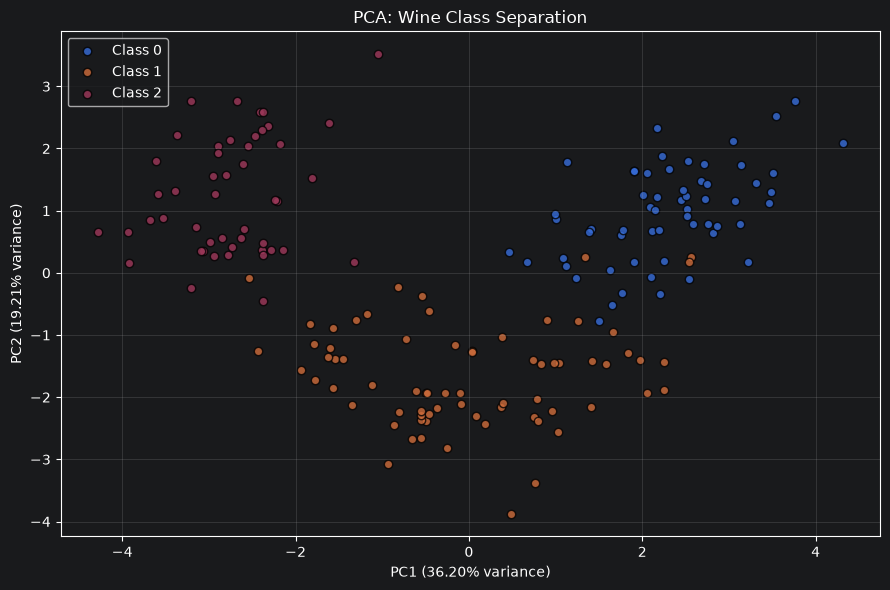

Explained variance ratio: [0.362  0.1921]
Total variance explained by two components: 55.41 %
Original data shape: (178, 13)
PCA data shape: (178, 2)


In [6]:
from sklearn.decomposition import PCA

# Create PCA with two principal components
pca = PCA(n_components=2)

# Transform the scaled data into two dimensions
X_pca = pca.fit_transform(X_scaled)

# Create a DataFrame for the PCA results
pca_df = pd.DataFrame(
    X_pca,
    columns=["Principal Component 1", "Principal Component 2"]
)

# Add the original class labels
pca_df["target"] = y.to_numpy()

# Plot each wine class using a different color
plt.figure(figsize=(9, 6))

for class_label in sorted(pca_df["target"].unique()):
    class_data = pca_df[pca_df["target"] == class_label]

    plt.scatter(
        class_data["Principal Component 1"],
        class_data["Principal Component 2"],
        label=f"Class {class_label}",
        alpha=0.8,
        edgecolors="black"
    )

# Add labels and title
plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}% variance)"
)
plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}% variance)"
)

plt.title("PCA: Wine Class Separation")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Display explained variance
print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))
print(
    "Total variance explained by two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

print("Original data shape:", X_scaled.shape)
print("PCA data shape:", X_pca.shape)

# Conclusion

## Principal Component Analysis (PCA) was applied to the standardized Wine dataset to reduce its 13 numerical features to two principal components. The resulting scatterplot visualized the three wine classes in two dimensions, making their patterns and separation easier to examine. The explained variance ratio showed how much of the dataset's total variation was represented by the two components. Thus, PCA provided a useful way to visualize high-dimensional data while retaining a substantial portion of its information.